In [6]:
%%HTML


<style type="text/css">

div.h2 {
     background-color: steelblue; 
     color: white; 
     padding: 8px; 
     padding-right: 300px; 
     font-size: 24px; 
     max-width: 1500px; 
     margin-top: 50px;
     margin-bottom:4px;
 }

Информация о базе данных:

В данной базе есть следующие категории:

Гендер: Полезно для анализа различий в успеваемости между студентами мужского и женского пола. (1 для мужчин и 0 для женщин)

Раса/этническая принадлежность: позволяет анализировать тенденции академической успеваемости среди различных расовых или этнических групп.

Уровень образования родителей: указывает уровень образования семьи учащегося.

Обед: показывает, получают ли студенты бесплатный обед или обед по льготной цене, что часто является социально-экономическим показателем.

Курс подготовки к экзамену: здесь указывается, прошли ли учащиеся курс подготовки к экзамену, который может повлиять на их успеваемость.

Оценка по математике: дает оценку успеваемости каждого учащегося по математике и используется для расчета средних значений или тенденций для различных демографических групп.

Оценка чтения: измеряет успеваемость в чтении, позволяя получить представление об уровне грамотности и понимания учащихся.

Оценка письма: оценивает навыки письма учащихся, которые можно проанализировать для оценки общей грамотности и выразительности.

Подготовка к работе: 

Скачиваем необходимые модули, такие как pandas, matplotlib, seaborn, kagglehub, sklearn. Также импортируем их

In [7]:
!pip install pandas
!pip install kagglehub
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

Загрузка набора данных

In [10]:
#path = kagglehub.dataset_download("muhammadroshaanriaz/students-performance-dataset-cleaned")
#print(path)
df = pd.read_csv(path + "/Cleaned_Students_Performance.csv")

NameError: name 'path' is not defined

Базовое исследование данных:

-Проверка недостающих или неверных данных.

-Очистка данных при необходимости

In [24]:
print(df.isnull().sum())
df.info()
df.describe()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
total_score                    0
average_score                  0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   int64  
 1   race_ethnicity               1000 non-null   object 
 2   parental_level_of_education  1000 non-null   object 
 3   lunch                        1000 non-null   int64  
 4   test_preparation_course      1000 non-null   int64  
 5   math_score                   1000 non-null   int64  
 6   reading_score                1000 non-null   int64  
 7   writing_score           

,gender,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.482000,0.645000,0.358000,66.08900,69.169000,68.054000,203.312000,67.770667
std,0.499926,0.478753,0.479652,15.16308,14.600192,15.195657,42.771978,14.257326
min,0.000000,0.000000,0.000000,0.00000,17.000000,10.000000,27.000000,9.000000
25%,0.000000,0.000000,0.000000,57.00000,59.000000,57.750000,175.000000,58.333333
50%,0.000000,1.000000,0.000000,66.00000,70.000000,69.000000,205.000000,68.333333
75%,1.000000,1.000000,1.000000,77.00000,79.000000,79.000000,233.000000,77.666667
max,1.000000,1.000000,1.000000,100.00000,100.000000,100.000000,300.000000,100.000000


Набор данных чист, никаких дальнейших манипуляций не требуется. Давайте посмотрим, как он выглядит

In [25]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,0,group B,bachelor's degree,1,0,72,72,74,218,72.666667
1,0,group C,some college,1,1,69,90,88,247,82.333333
2,0,group B,master's degree,1,0,90,95,93,278,92.666667
3,1,group A,associate's degree,0,0,47,57,44,148,49.333333
4,1,group C,some college,1,0,76,78,75,229,76.333333


Корреляция между академическим образованием родителей и средними баллами

NameError: name 'df' is not defined

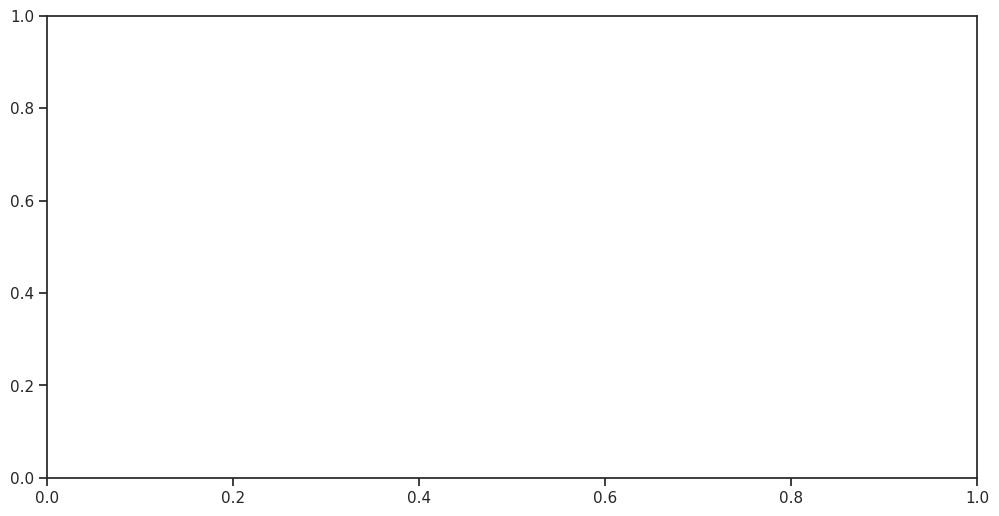

In [5]:
sns.set_theme(style="ticks")

# Initialize the figure with a linear x axis
f, ax = plt.subplots(figsize=(12, 6))
ax.set_xscale("linear")



# Plot the average_scores with horizontal boxes
sns.boxplot(
    df, x="parental_level_of_education", y="average_score", hue="parental_level_of_education",
    whis=[0, 100], width=.4, palette="vlag"
)

# Add in points to show each student
sns.stripplot(df, x="parental_level_of_education", y="average_score", size=4, color=".3")

# Tweak the visual presentation
ax.xaxis.grid(True)
ax.set(ylabel="")
sns.despine(trim=True, left=True)

plt.title('Корреляция между академическим образованием родителей и средними баллами')
plt.show()

Легко заметить, что самые высокие средние баллы имеют студенты, родители которых имеют степень магистра. Кроме того, их баллы не так сильно различаются, как у других (например, баллы детей, родители которых только закончили какую-то среднюю школу). В то же время, независимо от происхождения, каждый может получить высокие баллы.

Корреляция между академическим образованием и социально-экономической ситуацией

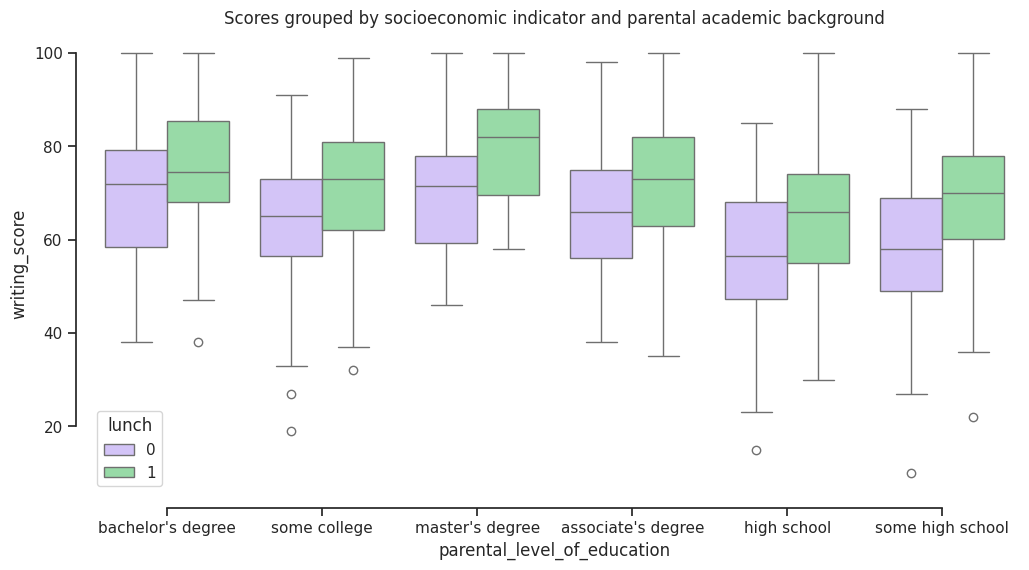

In [14]:
sns.set_theme(style="ticks", palette="pastel")
f, ax = plt.subplots(figsize=(12, 6))


# Draw a nested boxplot to show writing scores by socioeconomic indicator and parental academic background
sns.boxplot(x="parental_level_of_education", y="writing_score",
            hue="lunch", palette=["m", "g"],
            data=df)
sns.despine(offset=10, trim=True)

plt.title('Корреляция между академическим образованием и социально-экономической ситуацией')
plt.show()

График показывает, что люди, получающие бесплатный, имеют значительно более низкие баллы во всех группах.

Разница в результатах между мужчинами и женщинами

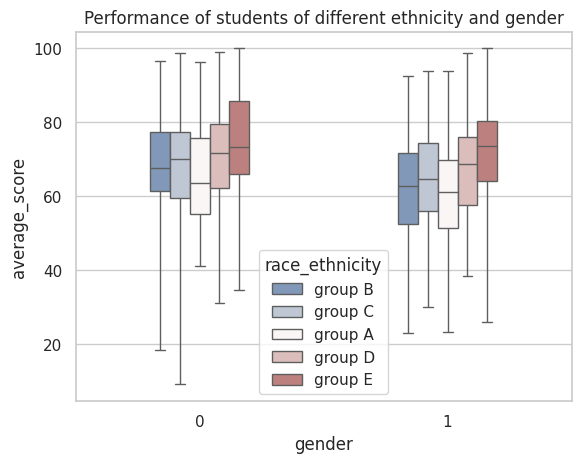

In [15]:

sns.set_theme(style="whitegrid", palette="muted")
# Plot the average_scores with horizontal boxes with hue of race_ethnicity also divided by gender
sns.boxplot(
    df, x="gender", y="average_score", hue="race_ethnicity",
    whis=[0, 100], width=.4, palette="vlag"
)
plt.title('Результаты учащихся разной национальности и пола')
plt.show()

Можно заметить, что женщины (пол 0) в среднем имеют более высокие баллы, чем мужчины. Между разными этническими группами нет большой диспропорции. Лидирует группа E с результатом 80+ и группа A занимает последнее место со счетом около 55.

Разница между оценками по математике, чтению и письму.

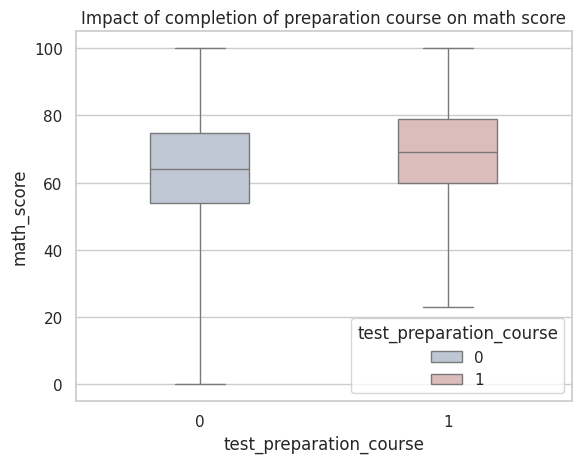

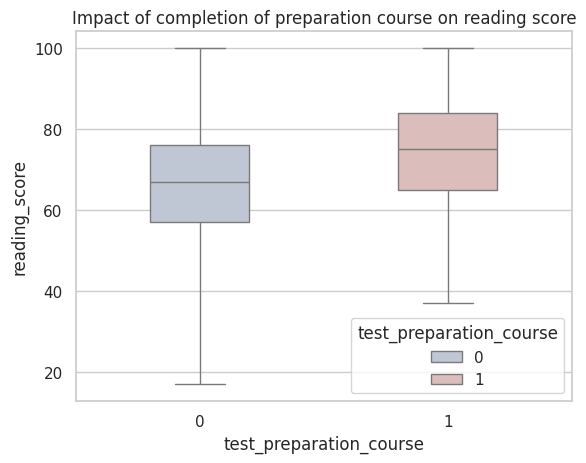

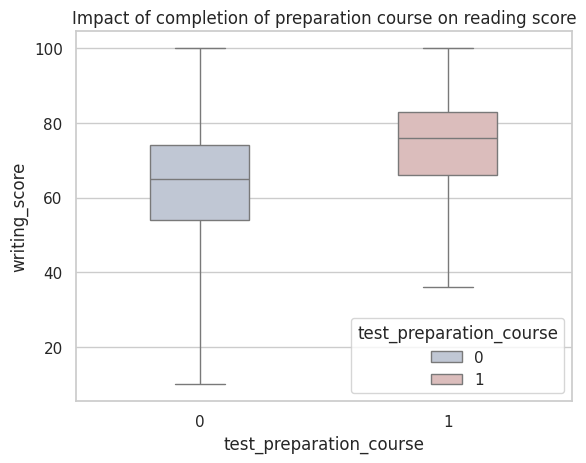

In [21]:
sns.boxplot(
    df, x="test_preparation_course", y="math_score", hue="test_preparation_course",
    whis=[0, 100], width=.4, palette="vlag"
)

plt.title('Влияние завершения подготовительного курса на оценку по математике')
plt.show()

sns.boxplot(
    df, x="test_preparation_course", y="reading_score", hue="test_preparation_course",
    whis=[0, 100], width=.4, palette="vlag"
)

plt.title('Влияние завершения подготовительного курса на оценку по чтению')
plt.show()

sns.boxplot(
    df, x="test_preparation_course", y="writing_score", hue="test_preparation_course",
    whis=[0, 100], width=.4, palette="vlag"
)

plt.title('Влияние завершения подготовительного курса на оценку по письму')
plt.show()

Учащиеся, прошедшие подготовительный курс по математике, не улучшают свои оценки так сильно, как те, кто закончил подготовительный курс по чтению или письму.

Матрица корреляции

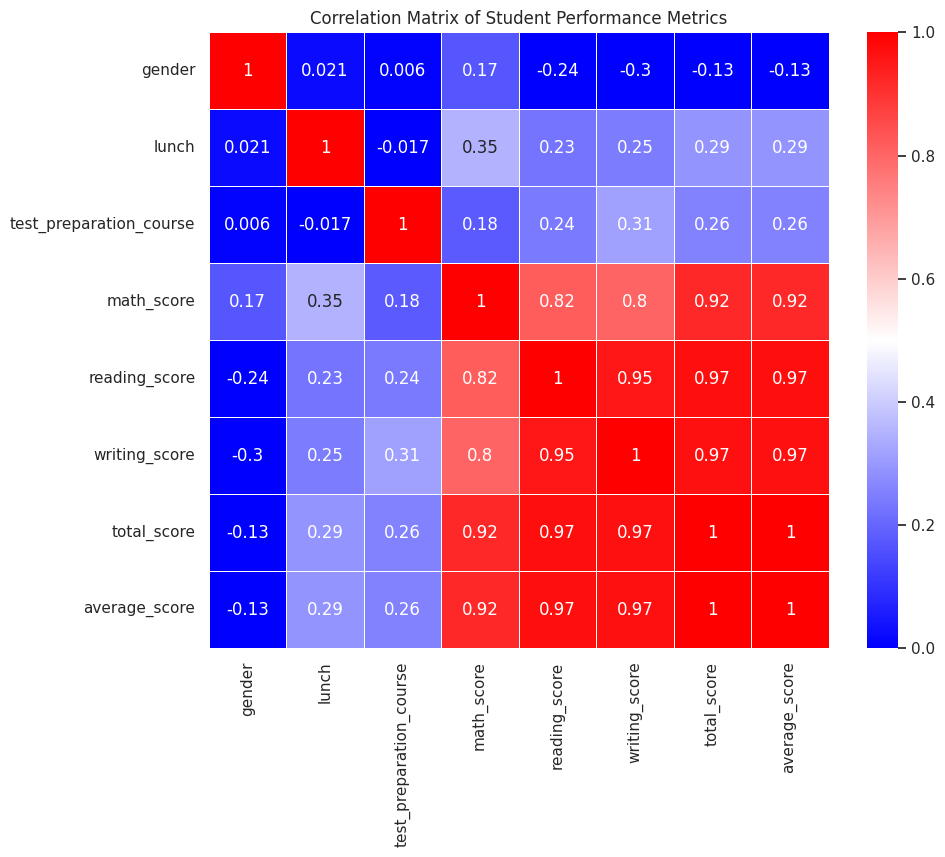

In [22]:
# Calculate correlation matrix for relevant columns
correlation_matrix = df[['gender', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'total_score', 'average_score']].corr()

# Set up matplotlib figure for heatmap
plt.figure(figsize=(10, 8))

# Create heatmap using seaborn
sns.heatmap(correlation_matrix, annot=True, cmap='bwr', vmin=0, vmax=1, linewidths=0.5)
# Add title and show plot

plt.title('Матрица корреляции показателей успеваемости учащихся')
plt.show()

Выводы:

На основе анализа набора данных об успеваемости учащихся можно сделать несколько выводов.

1) Различные социально-экономические факторы, такие как обед, пол, уровень образования родителей, этническая принадлежность, влияют на успеваемость учащихся.
2) Более высокие социально-экономические показатели обычно приводят к более высоким средним баллам.
3) Женщины показывают более высокие результаты в академической среде.
4) Большой разницы в оценках между людьми разных национальностей нет.
5) Курс подготовки к экзаменам улучшает результаты учащихся по всем предметам, но в большей степени по чтению и письму.